# Aviation Accidents Analysis

You are part of a consulting firm that is tasked to do an analysis of commercial and passenger jet airline safety. The client (an airline/airplane insurer) is interested in knowing what types of aircraft (makes/models) exhibit low rates of total destruction and low likelihood of fatal or serious passenger injuries in the event of an accident. They are also interested in any general variables/conditions that might be at play. Your analysis will be based off of aviation accident data accumulated from the years 1948-2023. 

Our client is only interested in airplane makes/models that are professional builds and could potentially still be active. Assume a max lifetime of 40 years for a make/model retirement and make sure to filter your data accordingly (i.e. from 1983 onwards). They would also like separate recommendations for small aircraft vs. larger passenger models. **In addition, make sure that claims that you make are statistically robust and that you have enough samples when making comparisons between groups.**


In this summative assessment you will demonstrate your ability to:
- Use Pandas to load, inspect, and clean the dataset appropriately. 
- Transform relevant columns to create measures that address the problem at hand.
- **conduct EDA: visualization and statistical measures to understand the structure of the data**
- **recommend a set of manufacturers to consider as well as specific airplanes conforming to the client's request**
- **discuss the relationship between serious injuries/airplane damage incurred and at least *two* factors at play in the incident. You must provide supporting evidence (visuals, summary statistics, tables) for each claim you make.**

In [1]:
# loading relevant packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Exploratory Data Analysis  
- Load in the cleaned data

In [2]:
# LOADING THE CLEANED DATA FROM PART ONE OF THE LAB
df = pd.read_csv('data/AviationData_Cleaned.csv', low_memory=False)

# Convert Event.Date back to datetime
df['Event.Date'] = pd.to_datetime(df['Event.Date'])

# Confirming it still matches the end of Part One (59795, 32)
print(df.shape)
df.head()

(59795, 32)


,Event.Id,Investigation.Type,Accident.Number,Event.Date,Location,Country,Latitude,Longitude,Airport.Code,Airport.Name,...,Total.Minor.Injuries,Total.Uninjured,Weather.Condition,Broad.phase.of.flight,Report.Status,Publication.Date,Total.Passengers,Fatal.Serious.Metric,Destroyed,Make.Model
0,20001214X42095,Accident,SEA83LA036,1983-01-01,"NEWPORT, OR",United States,NaN,NaN,ONP,NEWPORT MUNICIPAL,...,1.0,3.0,VMC,Approach,Probable Cause,NaN,4.0,0.0,0,Cessna 182P
1,20001214X42067,Accident,MKC83LA056,1983-01-01,"WOODBINE, IA",United States,NaN,NaN,3YR,MUNICIPAL,...,0.0,2.0,VMC,Landing,Probable Cause,NaN,2.0,0.0,0,Cessna 182RG
2,20001214X42063,Accident,MKC83LA050,1983-01-01,"MARYVILLE, MO",United States,NaN,NaN,78Y,RANKIN,...,0.0,1.0,VMC,Takeoff,Probable Cause,NaN,1.0,0.0,0,Cessna 182P
3,20001214X42018,Accident,LAX83FUG11,1983-01-01,"UPLAND, CA",United States,NaN,NaN,CCB,CABLE,...,2.0,0.0,VMC,Approach,Probable Cause,NaN,2.0,0.0,0,Piper PA-28R-200
4,20001214X41951,Accident,CHI83LA074,1983-01-01,"SPRINGBROOK, WI",United States,NaN,NaN,NaN,SPRINGBROOK,...,0.0,2.0,VMC,Landing,Probable Cause,NaN,2.0,0.0,0,Cessna 140


## Explore safety metrics across models/makes
- Remember that the client is interested in separate recommendations for smaller airplanes and larger airplanes. Choose a passenger threshold of 20 and separate the plane types. 

In [3]:
# SPLITTING INTO SMALL VS LARGE AIRPLANES

# Typical number of people on board for each plane type (median across its accidents)
typical_size = df.groupby('Make.Model')['Total.Passengers'].median()

# Plane types with a typical size of 20+ = Large, under 20 = Small
df['Size'] = np.where(df['Make.Model'].map(typical_size) >= 20, 'Large', 'Small')

df['Size'].value_counts()

Size
Small    58352
Large     1443
Name: count, dtype: int64

#### Analyzing Makes

Explore the human injury risk profile for small and larger Makes:
- choose the 15 makes for each group possessing the lowest mean fatal/seriously injured fraction
- plot the mean fatal/seriously injured fraction for each of these subgroups side-by-side

In [4]:
# ANALYZING MAKES: INJURY RATE BY MAKE (SMALL VS LARGE)

# Mean injury rate and number of accidents for each Make, within each size group:
make_stats = (df.groupby(['Size', 'Make'])['Fatal.Serious.Metric']
              .agg(['mean', 'count'])
              .reset_index())

# Keep makes with at least 10 accidents in that group:
make_stats = make_stats[make_stats['count'] >= 10]

# The 15 Makes with the lowest mean injury rate in each group:
small_makes = make_stats[make_stats['Size'] == 'Small'].nsmallest(15, 'mean')
large_makes =make_stats[make_stats['Size'] == 'Large'].nsmallest(15, 'mean')

print(small_makes)
print()
print(large_makes)

     Size               Make      mean  count
26  Small         Bombardier  0.072650     18
73  Small               Waco  0.102657    138
47  Small  Grumman-Schweizer  0.136775    184
50  Small              Helio  0.140620    105
55  Small              Maule  0.154766    570
43  Small        Great Lakes  0.161017     59
24  Small             Boeing  0.167046    492
25  Small    Boeing Stearman  0.180000     50
74  Small          Weatherly  0.188235     85
44  Small            Grumman  0.189256   1055
70  Small            Stinson  0.198139    421
71  Small         Swearingen  0.205109    145
20  Small              Aviat  0.206522    230
54  Small           Luscombe  0.221934    386
34  Small            Diamond  0.239501    127

     Size               Make      mean  count
13  Large  Mcdonnell Douglas  0.055407    230
2   Large         Bombardier  0.085096     75
12  Large           Lockheed  0.087644     28
4   Large           Canadair  0.097985     14
1   Large             Boeing  0.1

In [5]:
# CHECK: Which Boeing models are labeled Small?
df[(df['Make'] == 'Boeing') & (df['Size'] == 'Small')]['Model'].value_counts().head(10)

Model
A75N1           99
B75N1           43
E75             33
747             31
A75N1(PT17)     30
A75             21
E75N1           11
A75N1 (PT17)     9
PT-17            8
D75N1            8
Name: count, dtype: int64

**Note on "Boeing" in the Small group:** Most Small Boeing accidents are Stearman biplanes (models A75N1, B75N1, E75, PT-17) recorded under the Boeing name, not Boeing airliners. A few large aircraft (e.g., the 747) were also labeled Small because some reports only recorded injured occupants, so the estimated number of people on board is too low. Because of this, "Boeing" is not recommended as a small-aircraft Make, and passenger-based size estimates should be treated as approximate.

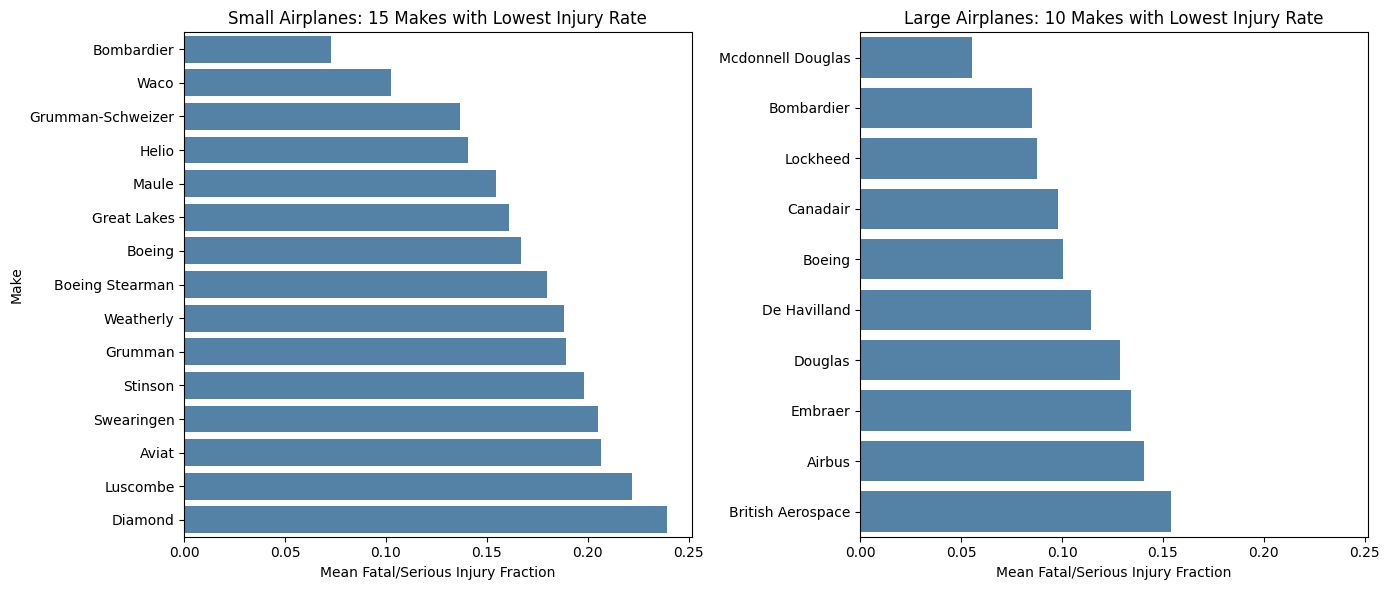

In [6]:
# PLOTTING: MAKES WITH THE LOWEST INJURY RATE (SMALL VS LARGE)

# Two plots side by side, sharing the same x-axis scale
fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharex=True)

# Left: small airplanes
sns.barplot(data=small_makes, x='mean', y='Make', color='steelblue', ax=axes[0])
axes[0].set_title('Small Airplanes: 15 Makes with Lowest Injury Rate')
axes[0].set_xlabel('Mean Fatal/Serious Injury Fraction')
axes[0].set_ylabel('Make')

# Right: large airplanes
sns.barplot(data=large_makes, x='mean', y='Make', color='steelblue', ax=axes[1])
axes[1].set_title('Large Airplanes: 10 Makes with Lowest Injury Rate')
axes[1].set_xlabel('Mean Fatal/Serious Injury Fraction')
axes[1].set_ylabel('')

plt.tight_layout()
plt.show()

**Distribution of injury rates: small makes**

Use a violinplot to look at the distribution of the fraction of passengers serious/fatally injured for small airplane makes. Just display makes with the ten lowest mean serious/fatal injury rates.

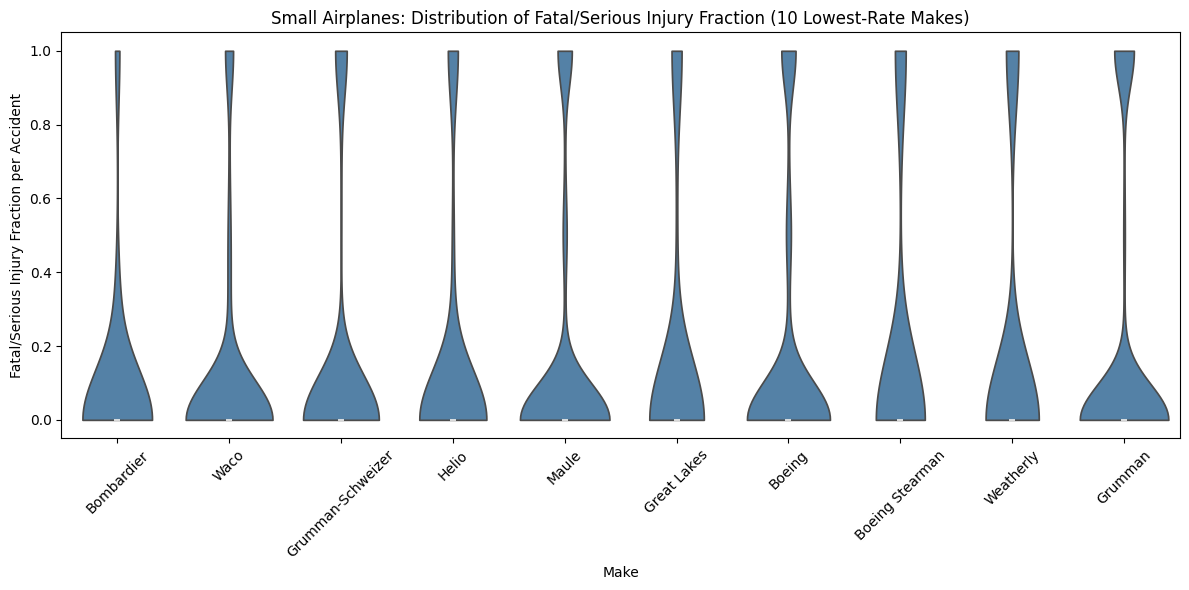

In [7]:
# DISTRIBUTION OF INJURY RATES: SMALL MAKES (VIOLIN PLOT)

# The 10 small Makes with the lowest mean injury rate:
top10_small = small_makes.nsmallest(10, 'mean')['Make']

# All individual small-airplane accidents for those Makes:
small_top10_df = df[(df['Size'] == 'Small') & (df['Make'].isin(top10_small))]

# Create violin plot:
plt.figure(figsize=(12, 6))
sns.violinplot(data=small_top10_df, x='Make', y='Fatal.Serious.Metric',
               order=top10_small, color='steelblue', cut=0)
plt.title('Small Airplanes: Distribution of Fatal/Serious Injury Fraction (10 Lowest-Rate Makes)')
plt.xlabel('Make')
plt.ylabel('Fatal/Serious Injury Fraction per Accident')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Distribution of injury rates: large makes**

Use a stripplot to look at the distribution of the fraction of passengers serious/fatally injured for large airplane makes. Just display makes with the ten lowest mean serious/fatal injury rates.

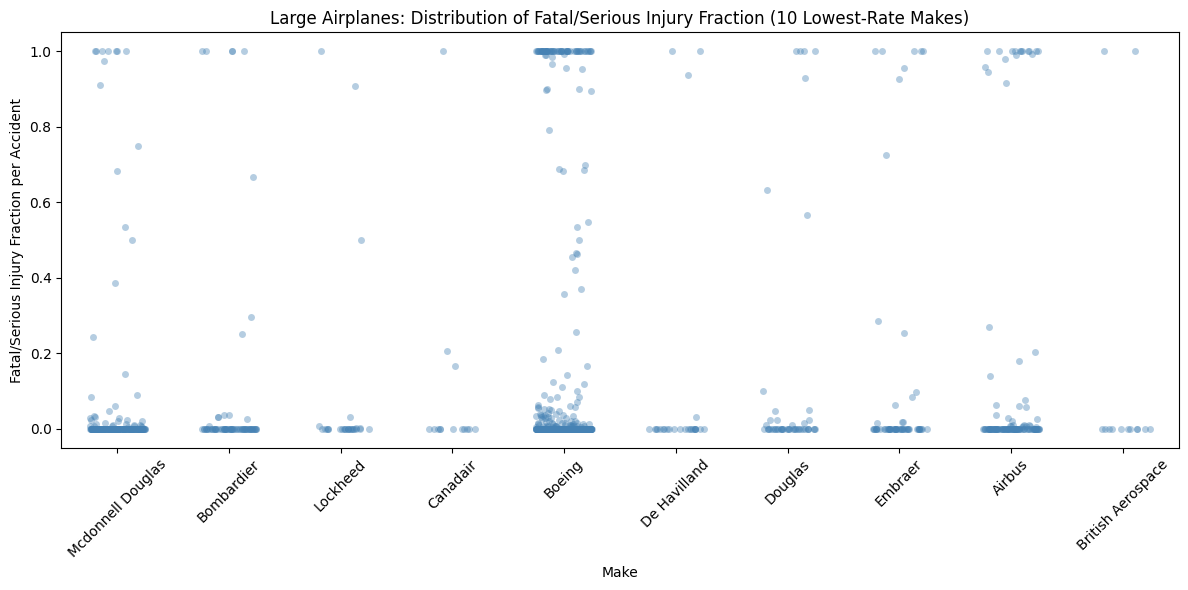

In [8]:
# DISTRIBUTION OF INJURY RATES: LARGE MAKES (STRIP PLOT)

# The 10 large Makes with the lowest mean injury rate:
top10_large = large_makes.nsmallest(10, 'mean')['Make']

# All individual large-airplane accidents for those Makes:
large_top10_df = df[(df['Size'] == 'Large') & (df['Make'].isin(top10_large))]

# Create strip plot:
plt.figure(figsize=(12, 6))
sns.stripplot(data=large_top10_df, x='Make', y='Fatal.Serious.Metric',
              order=top10_large, color='steelblue', alpha=0.4, jitter=0.25)
plt.title('Large Airplanes: Distribution of Fatal/Serious Injury Fraction (10 Lowest-Rate Makes)')
plt.xlabel('Make')
plt.ylabel('Fatal/Serious Injury Fraction per Accident')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Evaluate the rate of aircraft destruction for both small and large aircraft by Make.** 

Sort your results and keep the lowest 15.

In [9]:
# DESTRUCTION RATE BY MAKE (SMALL VS LARGE)

# Destruction rate (mean of the 0/1 column) and accident count for each Make, within each size group:
destroyed_stats = (df.groupby(['Size', 'Make'])['Destroyed']
                   .agg(['mean', 'count'])
                   .reset_index())

# Keep makes with at least 10 accidents in that group:
destroyed_stats = destroyed_stats[destroyed_stats['count'] >= 10]

# Sort and keep the lowest 15 destruction rates in each group:
small_destroyed = destroyed_stats[destroyed_stats['Size'] == 'Small'].nsmallest(15, 'mean')
large_destroyed = destroyed_stats[destroyed_stats['Size'] == 'Large'].nsmallest(15, 'mean')

print(small_destroyed)
print()
print(large_destroyed)

     Size                    Make      mean  count
34  Small                 Diamond  0.055118    127
26  Small              Bombardier  0.055556     18
40  Small           Flight Design  0.060000     50
20  Small                   Aviat  0.069565    230
73  Small                    Waco  0.086957    138
55  Small                   Maule  0.092982    570
37  Small                 Ercoupe  0.094595     74
25  Small         Boeing Stearman  0.100000     50
19  Small       American Champion  0.102941     68
54  Small                Luscombe  0.103627    386
46  Small    Grumman American Avn  0.120000     50
72  Small             Taylorcraft  0.122951    366
50  Small                   Helio  0.123810    105
24  Small                  Boeing  0.130081    492
66  Small  Rockwell International  0.130435     69

     Size               Make      mean  count
2   Large         Bombardier  0.080000     75
13  Large  Mcdonnell Douglas  0.086957    230
1   Large             Boeing  0.107407    810

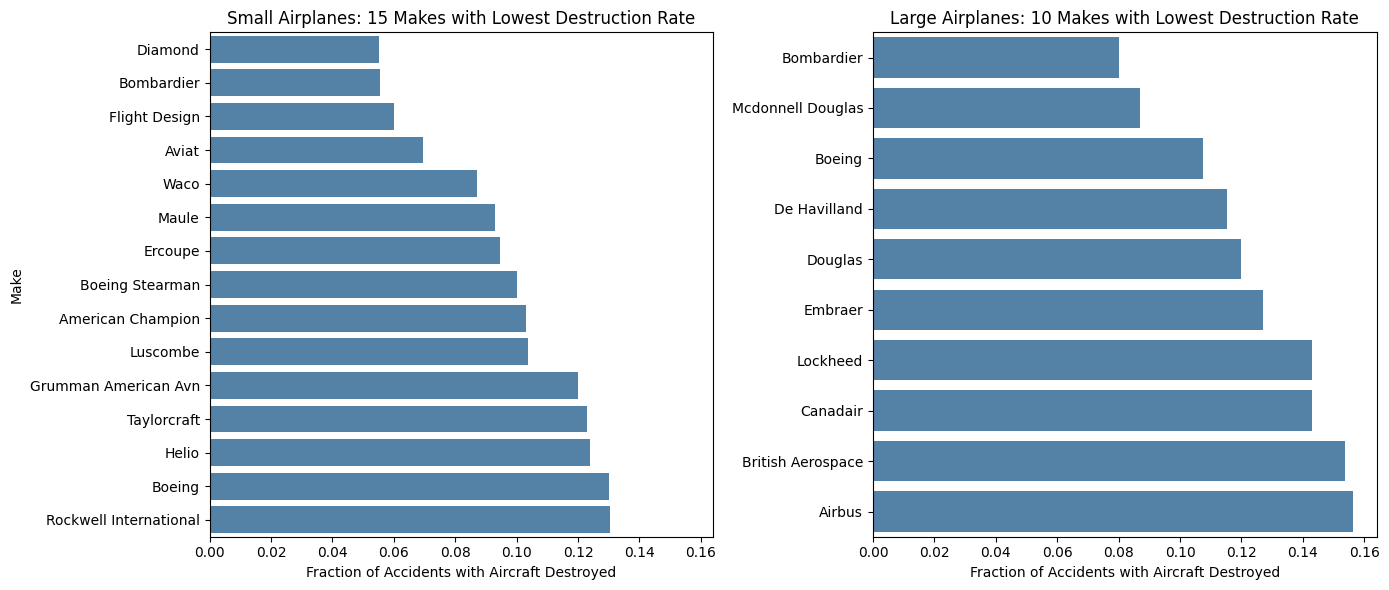

In [10]:
# PLOTTING: MAKES WITH THE LOWEST DESTRUCTION RATE (SMALL VS LARGE)

fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharex=True)

# Left: small airplanes
sns.barplot(data=small_destroyed, x='mean', y='Make', color='steelblue', ax=axes[0])
axes[0].set_title('Small Airplanes: 15 Makes with Lowest Destruction Rate')
axes[0].set_xlabel('Fraction of Accidents with Aircraft Destroyed')
axes[0].set_ylabel('Make')

# Right: large airplanes
sns.barplot(data=large_destroyed, x='mean', y='Make', color='steelblue', ax=axes[1])
axes[1].set_title('Large Airplanes: 10 Makes with Lowest Destruction Rate')
axes[1].set_xlabel('Fraction of Accidents with Aircraft Destroyed')
axes[1].set_ylabel('')

plt.tight_layout()
plt.show()

In [11]:
# COMBINING BOTH SAFETY MEASURES FOR EACH MAKE

# Join the injury table and the destruction table on Size + Make
combined = make_stats.merge(destroyed_stats, on=['Size', 'Make', 'count'],
                            suffixes=('_injury', '_destroyed'))

# Show each group sorted by injury rate, with destruction rate alongside
for size in ['Small', 'Large']:
    print(size)
    print(combined[combined['Size'] == size].sort_values('mean_injury').head(15))
    print()

Small
     Size               Make  mean_injury  count  mean_destroyed
22  Small         Bombardier     0.072650     18        0.055556
69  Small               Waco     0.102657    138        0.086957
43  Small  Grumman-Schweizer     0.136775    184        0.179348
46  Small              Helio     0.140620    105        0.123810
51  Small              Maule     0.154766    570        0.092982
39  Small        Great Lakes     0.161017     59        0.135593
20  Small             Boeing     0.167046    492        0.130081
21  Small    Boeing Stearman     0.180000     50        0.100000
70  Small          Weatherly     0.188235     85        0.211765
40  Small            Grumman     0.189256   1055        0.245498
66  Small            Stinson     0.198139    421        0.133017
67  Small         Swearingen     0.205109    145        0.200000
16  Small              Aviat     0.206522    230        0.069565
50  Small           Luscombe     0.221934    386        0.103627
30  Small          

#### Provide a short discussion on your findings for your summary statistics and plots:
- Make any recommendations for Makes here based off of the destroyed fraction and fraction fatally/seriously injured
- Comment on the calculated statistics and any corresponding distributions you have visualized.

## Make Recommendations

To be recommended, a Make had to have a **low fatal/serious injury rate**, a **low destruction rate**, and **enough accidents (10+ in its size group) for the averages to be reliable**.

### Small airplanes (fewer than 20 people typical)
| Make | Injury rate | Destroyed rate | Accidents |
|---|---|---|---|
| **Maule** | 15.5% | 9.3% | 570 |
| **Waco** | 10.3% | 8.7% | 138 |
| **Aviat** | 20.7% | 7.0% | 230 |

- **Maule** is the strongest recommendation: low on both measures and backed by the largest sample among the top performers.
- **Waco** has low rates on both measures with a solid sample.
- **Aviat** has one of the lowest destruction rates, with a moderate injury rate.
- **Not recommended despite low rates:** Bombardier (only 18 small-aircraft accidents, too few to trust) and "Boeing" (mostly Stearman biplanes recorded under the Boeing name, not modern aircraft).
- **Trade-off example:** Diamond has the lowest destruction rate (5.5%) but a high injury rate (24%). This shows the two measures don't always agree.

### Large airplanes (20+ people typical)
| Make | Injury rate | Destroyed rate | Accidents |
|---|---|---|---|
| **McDonnell Douglas** | 5.5% | 8.7% | 230 |
| **Bombardier** | 8.5% | 8.0% | 75 |
| **Boeing** | 10.0% | 10.7% | 810 |

- **McDonnell Douglas** has the lowest injury rate and the second-lowest destruction rate, with a large sample. **Caveat:** McDonnell Douglas merged into Boeing in 1997 and many of its models are no longer produced, so the client should confirm which aircraft are still active.
- **Bombardier** is low on both measures.
- **Boeing** is slightly higher, but is backed by by far the most data (810 accidents), making its rates the most reliable.
- **Not recommended despite low rates:** Lockheed (28), Canadair (14), and British Aerospace (13) have too few accidents to draw reliable conclusions.

### Comments on the statistics and distributions
- For both small and large airplanes, **most accidents result in no fatal or serious injuries**. The distributions are heavily concentrated at 0, with a smaller cluster at 1 (everyone on board injured).
- **Small-airplane outcomes are close to all-or-nothing** (violin plot): small planes carry 1–4 people, so a single serious injury often means a fraction of 1.0.
- **Large-airplane outcomes include more in-between values** (strip plot), because one injury among 150 passengers is a small fraction.
- **Large airplanes have lower injury rates overall** than small airplanes (mostly under 15% vs. 15–22%).
- **Sample size matters:** Makes with few accidents can rank near the top by chance, so recommendations favor Makes with both low rates *and* large samples.

### Analyze plane types
- plot the mean fatal/seriously injured fraction for both small and larger planes 
- also provide a distributional plot of your choice for the fatal/seriously injured fraction by airplane type (stripplot, violin, etc)  
- filter ensuring that you have at least ten individual examples in each model/make to average over

**Larger planes**

In [12]:
# LARGER PLANES: INJURY RATE BY PLANE TYPE (MAKE.MODEL)

# Mean injury rate and accident count for each large plane type:
large_models = (df[df['Size'] == 'Large']
                .groupby('Make.Model')['Fatal.Serious.Metric']
                .agg(['mean', 'count'])
                .reset_index())

# Keep plane types with at least 10 accidents, sort safest first
large_models = large_models[large_models['count'] >= 10].sort_values('mean')

print('Large plane types with 10+ accidents:', len(large_models))
large_models

Large plane types with 10+ accidents: 32


,Make.Model,mean,count
202,Boeing 757-232,0.000000,10
198,Boeing 757-222,0.000000,10
236,Boeing 777,0.000000,24
428,Mcdonnell Douglas MD-83,0.000938,13
425,Mcdonnell Douglas MD-80,0.000978,11
430,Mcdonnell Douglas MD-88,0.002760,20
410,Mcdonnell Douglas DC-9-51,0.005693,11
399,Mcdonnell Douglas DC-10-10,0.028679,19
290,Bombardier CL-600-2B19,0.030617,26
72,Boeing 727-200,0.043742,24


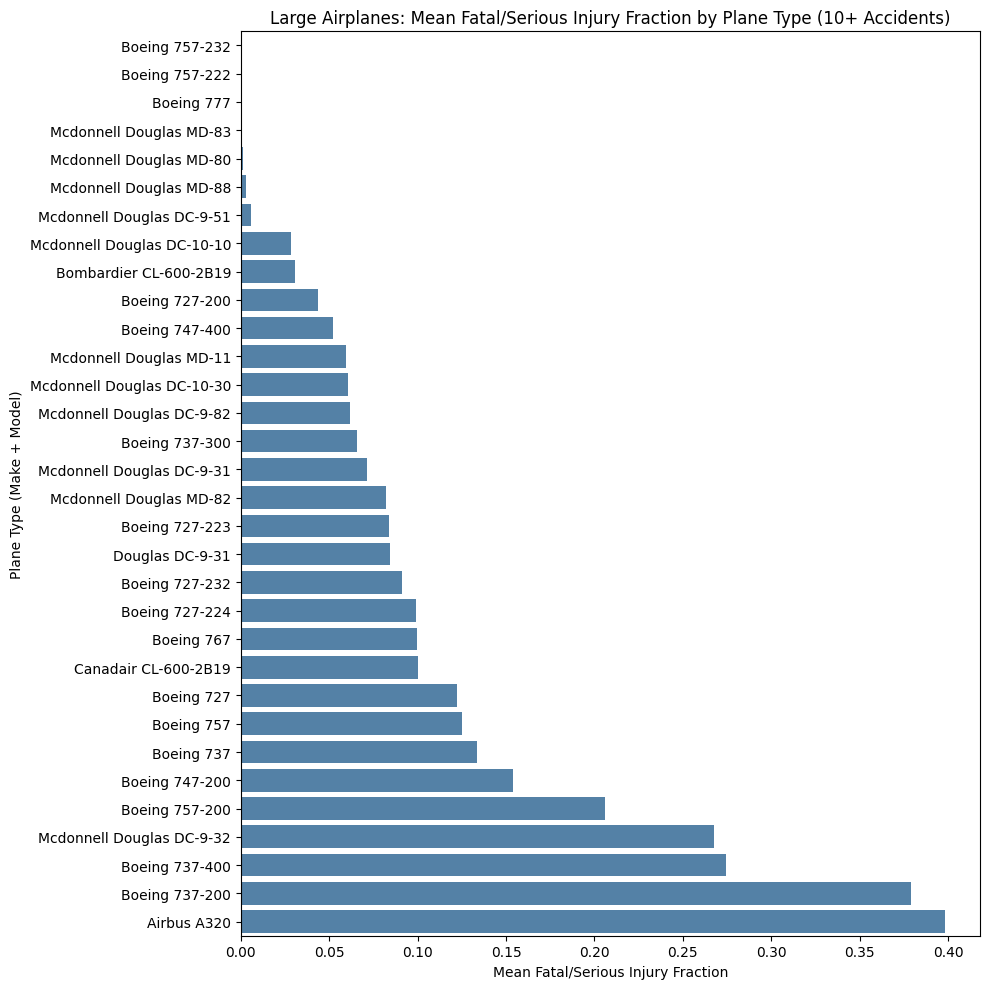

In [13]:
# PLOTTING: MEAN INJURY RATE FOR LARGE PLANE TYPES

plt.figure(figsize=(10, 10))
sns.barplot(data=large_models, x='mean', y='Make.Model', color='steelblue')
plt.title('Large Airplanes: Mean Fatal/Serious Injury Fraction by Plane Type (10+ Accidents)')
plt.xlabel('Mean Fatal/Serious Injury Fraction')
plt.ylabel('Plane Type (Make + Model)')
plt.tight_layout()
plt.show()

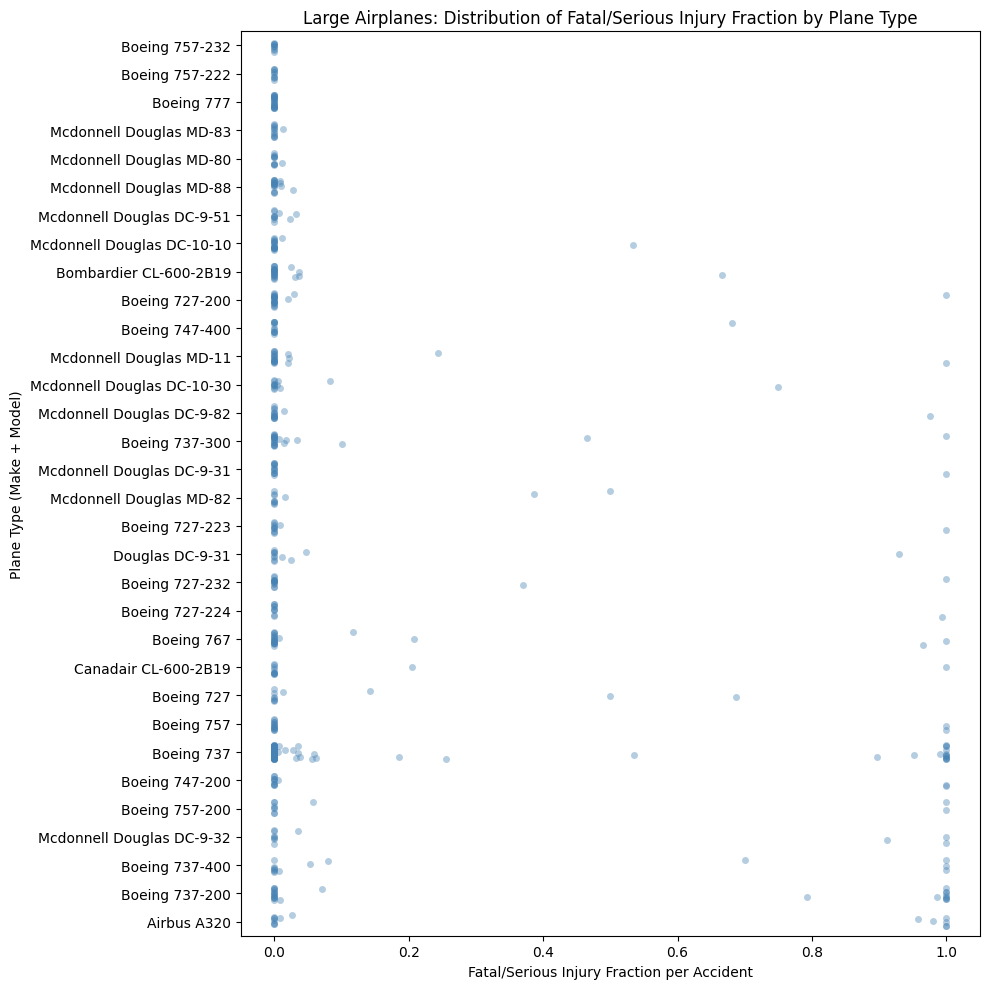

In [14]:
# DISTRIBUTION: INJURY FRACTION FOR LARGE PLANE TYPES (STRIP PLOT)

# All individual accidents for the qualifying large plane types
large_models_df = df[(df['Size'] == 'Large') & (df['Make.Model'].isin(large_models['Make.Model']))]

plt.figure(figsize=(10, 10))
sns.stripplot(data=large_models_df, x='Fatal.Serious.Metric', y='Make.Model',
              order=large_models['Make.Model'], color='steelblue', alpha=0.4, jitter=0.25)
plt.title('Large Airplanes: Distribution of Fatal/Serious Injury Fraction by Plane Type')
plt.xlabel('Fatal/Serious Injury Fraction per Accident')
plt.ylabel('Plane Type (Make + Model)')
plt.tight_layout()
plt.show()

**Smaller planes**
- for smaller planes, limit your plotted results to the makes with the 10 lowest mean serious/fatal injury fractions

In [15]:
# SMALLER PLANES: INJURY RATE BY PLANE TYPE (MAKE.MODEL)

# Mean injury rate and accident count for each small plane type (keeping Make as a column)
small_models = (df[df['Size'] == 'Small']
                  .groupby(['Make', 'Make.Model'])['Fatal.Serious.Metric']
                  .agg(['mean', 'count'])
                  .reset_index())

# Keep plane types with at least 10 accidents
small_models = small_models[small_models['count'] >= 10]

# Limit to plane types from the 10 small Makes with the lowest injury rate (top10_small from the violin plot)
small_models_top = small_models[small_models['Make'].isin(top10_small)].sort_values('mean')

print('Small plane types with 10+ accidents:', len(small_models))
print('Plane types from the 10 safest small Makes:', len(small_models_top))
small_models_top

Small plane types with 10+ accidents: 746
Plane types from the 10 safest small Makes: 52


,Make,Make.Model,mean,count
2534,Grumman,Grumman G164B,0.000000,16
2922,Maule,Maule MX-7-235,0.029412,17
2868,Maule,Maule M-7-235B,0.050000,10
2473,Grumman,Grumman AA1B,0.050000,10
2841,Maule,Maule M-4,0.055556,18
2606,Grumman-Schweizer,Grumman-Schweizer G-164A,0.062147,59
1011,Boeing,Boeing 747,0.067594,31
4312,Weatherly,Weatherly 201B,0.074074,27
1088,Boeing,Boeing E75,0.075758,33
1120,Boeing Stearman,Boeing Stearman A75N1,0.076923,13


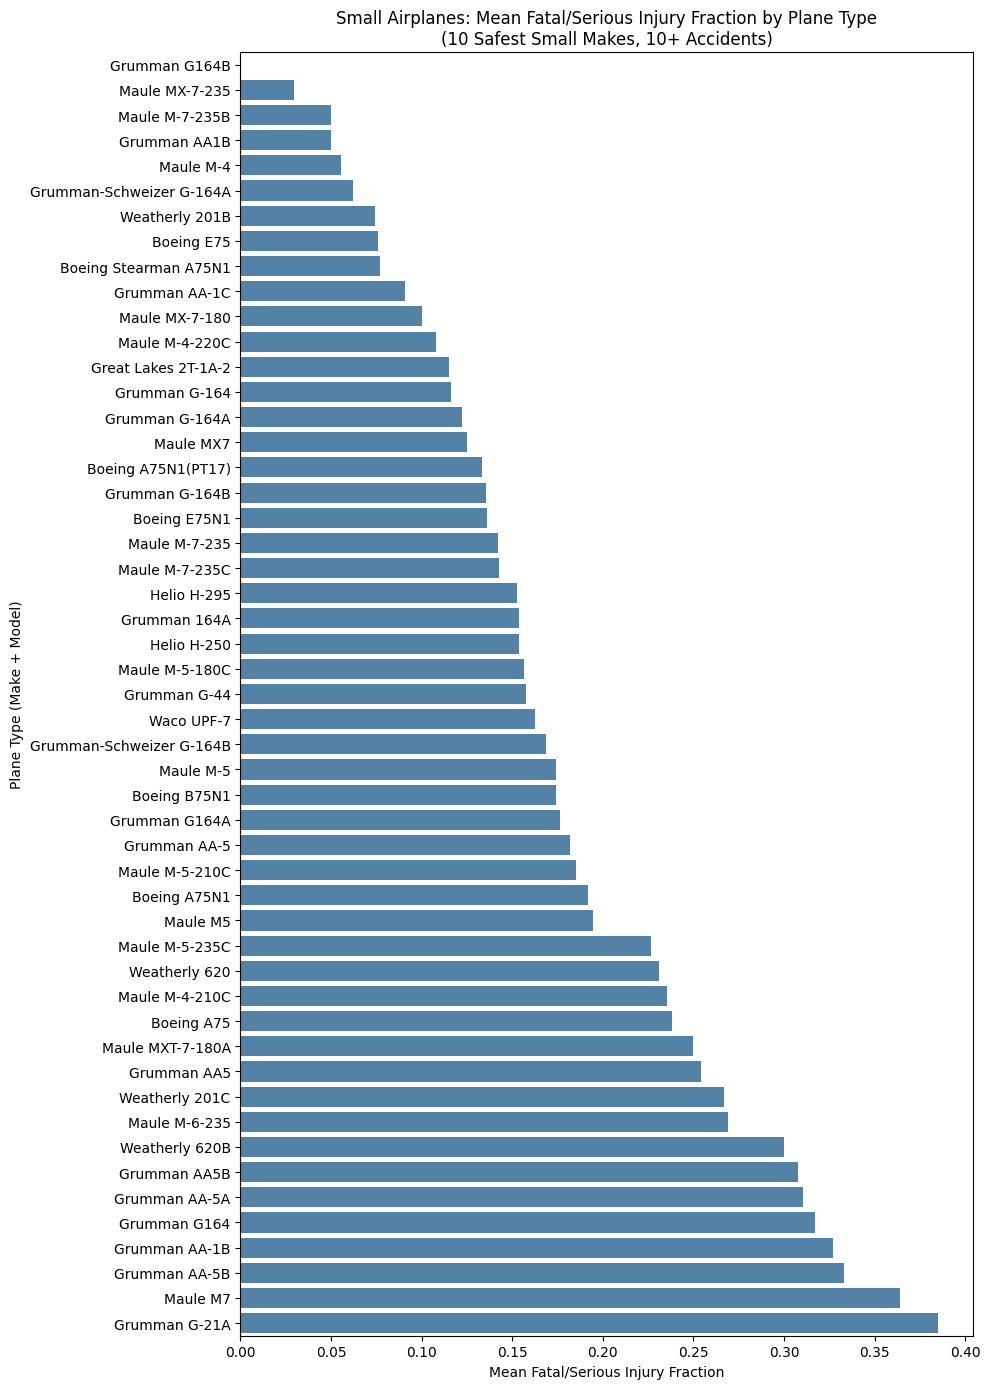

In [16]:
# PLOTTING: MEAN INJURY RATE FOR SMALL PLANE TYPES (FROM THE 10 SAFEST SMALL MAKES)

# Remove the Boeing 747 (a large plane misclassified as small; see earlier note)
small_models_top = small_models_top[small_models_top['Make.Model'] != 'Boeing 747']

plt.figure(figsize=(10, 14))
sns.barplot(data=small_models_top, x='mean', y='Make.Model', color='steelblue')
plt.title('Small Airplanes: Mean Fatal/Serious Injury Fraction by Plane Type\n(10 Safest Small Makes, 10+ Accidents)')
plt.xlabel('Mean Fatal/Serious Injury Fraction')
plt.ylabel('Plane Type (Make + Model)')
plt.tight_layout()
plt.show()


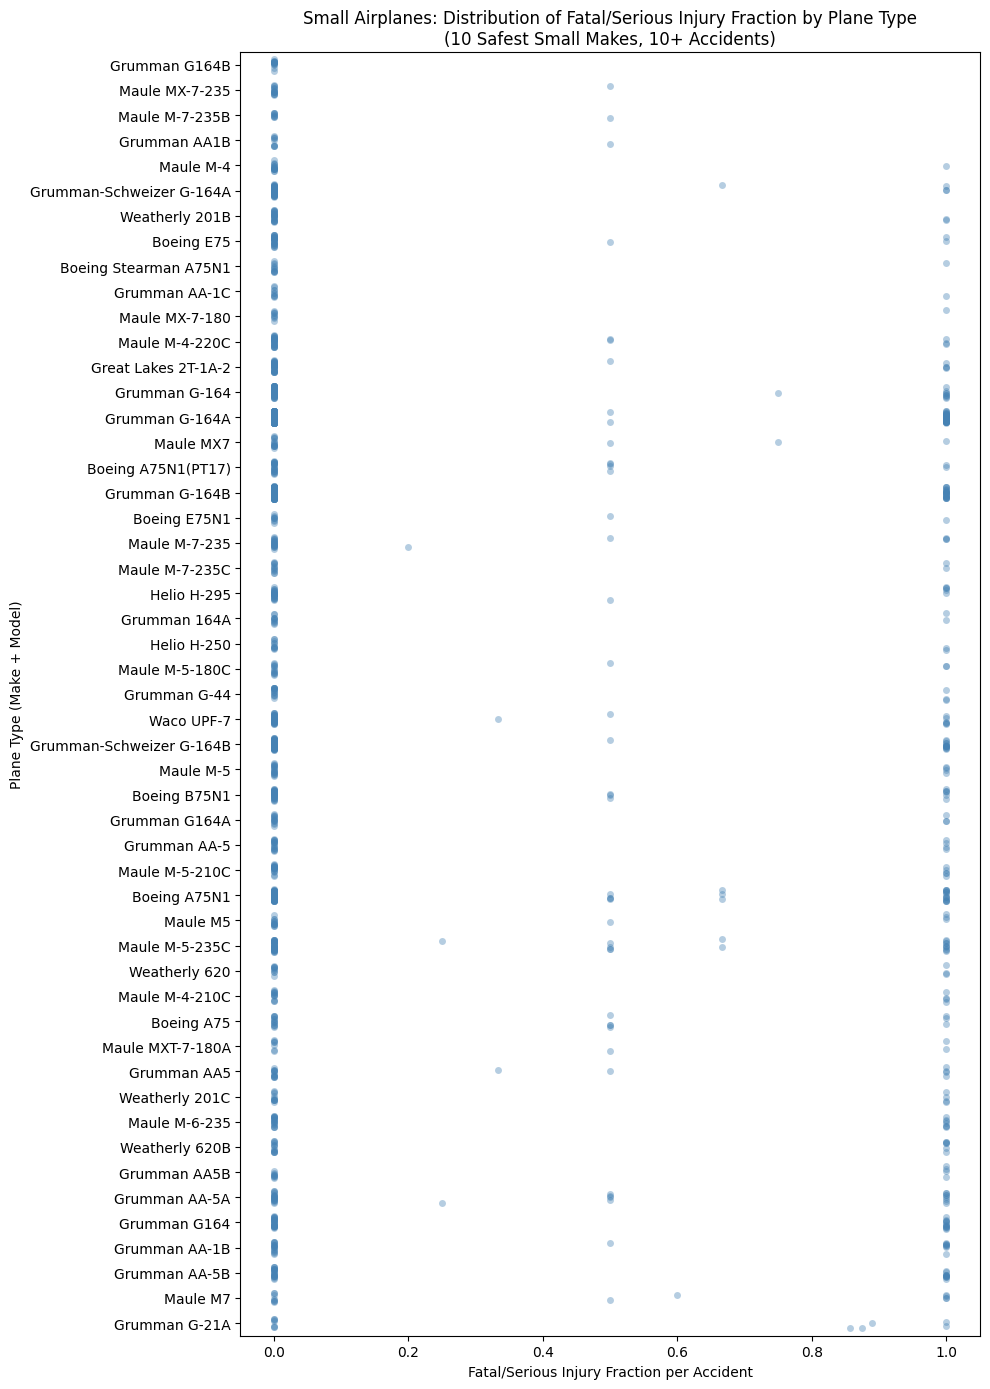

In [17]:
# DISTRIBUTION: INJURY FRACTION FOR SMALL PLANE TYPES (STRIP PLOT)

# All individual small-plane accidents for the plotted plane types
small_models_df = df[(df['Size'] == 'Small') & (df['Make.Model'].isin(small_models_top['Make.Model']))]

plt.figure(figsize=(10, 14))
sns.stripplot(data=small_models_df, x='Fatal.Serious.Metric', y='Make.Model',
              order=small_models_top['Make.Model'], color='steelblue', alpha=0.4, jitter=0.25)
plt.title('Small Airplanes: Distribution of Fatal/Serious Injury Fraction by Plane Type\n(10 Safest Small Makes, 10+ Accidents)')
plt.xlabel('Fatal/Serious Injury Fraction per Accident')
plt.ylabel('Plane Type (Make + Model)')
plt.tight_layout()
plt.show()

### Discussion of Specific Airplane Types
- Discuss what you have found above regarding passenger fraction seriously/ both small and large airplane models.

## Discussion of Specific Airplane Types

Only plane types (Make + Model) with **at least 10 accidents** were included, so each average is based on a reasonable number of events.

### Large airplanes
| Plane type | Injury rate | Accidents |
|---|---|---|
| **Boeing 777** | 0.0% | 24 |
| **McDonnell Douglas MD-80 family** (MD-80, MD-83, MD-88) | under 0.3% | 11–20 each |
| **Bombardier CL-600-2B19** (CRJ regional jet) | 3.1% | 26 |

- The **Boeing 777** had no fatal or serious injuries in 24 accidents. Combined with Boeing's large overall sample at the Make level, it is the strongest large-aircraft recommendation.
- The **MD-80 family** had nearly zero injury rates, but these aircraft are no longer produced and many have been retired, so the client should confirm they are still in active service.
- The **Bombardier CL-600-2B19** is a strong choice for regional (smaller passenger) jets.
- The **Airbus A320 (39.8%)** and **Boeing 737-200 (37.9%)** had the highest rates. The strip plot shows this is driven by a **few severe accidents**: most of their accidents had no injuries. With only 15–26 accidents each, a few events strongly affect the average.

### Small airplanes (plane types from the 10 safest small Makes)
| Plane type | Injury rate | Accidents |
|---|---|---|
| **Grumman-Schweizer G-164A** | 6.2% | 59 |
| **Maule M-4-220C** | 10.8% | 37 |
| **Grumman G-164A** | 12.2% | 335 |

- These combine low injury rates with the largest sample sizes among the top performers. The **Grumman G-164A** has the most data (335 accidents) of any plane in this group.
- Several plane types near the top (e.g., Maule MX-7-235 at 2.9%) have only 10–17 accidents, so they are promising but less certain.
- **Business consideration:** many top small plane types are **specialized aircraft**. The Grumman G-164 (Ag-Cat) is an agricultural crop duster, and the Boeing/Stearman models are WWII-era biplanes. The client should consider whether these match the aircraft they insure. **Maule** (general-purpose bush/utility planes) may be the more broadly applicable small-aircraft recommendation.

### Distributions and limitations
- For both sizes, **most accidents result in no fatal or serious injuries**. Averages are pulled up by a small number of severe accidents.
- **Small-plane outcomes cluster at 0, 0.5, and 1.0**, because these planes usually carry 1–2 people.
- **Model names are recorded inconsistently** (e.g., "G164B" vs. "G-164B", or "737" vs. "737-300"), which splits some plane types into separate rows with smaller samples. Standardizing model names would be a useful next step.

### Exploring Other Variables
- Investigate how other variables effect aircraft damage and injury. You must choose **two** factors out of the following but are free to analyze more:

- Weather Condition
- Engine Type
- Number of Engines
- Phase of Flight
- Purpose of Flight

For each factor provide a discussion explaining your analysis with appropriate visualization / data summaries and interpreting your findings.

In [18]:
# FACTOR #1: WEATHER CONDITIONS

# Injury rate, destruction rate, and number of accidents for each weather condition:
weather_stats = df.groupby('Weather.Condition').agg(
    injury_rate = ('Fatal.Serious.Metric', 'mean'),
    destroyed_rate = ('Destroyed', 'mean'),
    accidents = ('Destroyed', 'count')
)

weather_stats

,injury_rate,destroyed_rate,accidents
Weather.Condition,,,
IMC,0.664178,0.583750,4800
VMC,0.222272,0.168547,52484


IMC (bad weather): 66% injury rate and 58% destroyed
<br>
VMC (clear weather): 22% injury rate and 17% destroyed

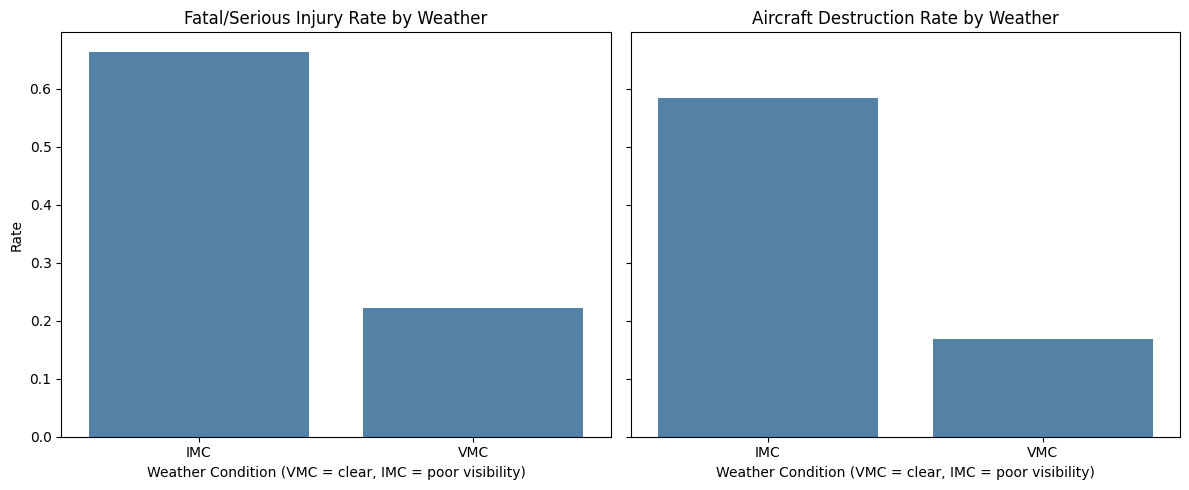

In [19]:
# PLOTTING: WEATHER CONDITION VS. INJURY AND DESTRUCTION RATES

weather_plot = weather_stats.reset_index()

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)

# Left: injury rate
sns.barplot(data=weather_plot, x='Weather.Condition', y='injury_rate', color='steelblue', ax=axes[0])
axes[0].set_title('Fatal/Serious Injury Rate by Weather')
axes[0].set_xlabel('Weather Condition (VMC = clear, IMC = poor visibility)')
axes[0].set_ylabel('Rate')

# Right: destruction rate
sns.barplot(data=weather_plot, x='Weather.Condition', y='destroyed_rate', color='steelblue', ax=axes[1])
axes[1].set_title('Aircraft Destruction Rate by Weather')
axes[1].set_xlabel('Weather Condition (VMC = clear, IMC = poor visibility)')
axes[1].set_ylabel('')

plt.tight_layout()
plt.show()

In [20]:
# CHECK: Does the weather effect hold for both small planes and large planes?

weather_by_size = df.groupby(['Size', 'Weather.Condition']).agg(
    injury_rate = ('Fatal.Serious.Metric', 'mean'),
    destroyed_rate = ('Destroyed', 'mean'),
    accidents = ('Destroyed', 'count')
)

weather_by_size

injury_rate  destroyed_rate  accidents
Size  Weather.Condition                                        
Large IMC                   0.195831        0.220513        195
      VMC                   0.046659        0.049482        869
Small IMC                   0.684011        0.599131       4605
      VMC                   0.225229        0.170551      51615

|  | IMC injury | VMC injury | IMC destroyed | VMC destroyed |
|---|---|---|---|---|
| **Small** | 68.4% | 22.5% | 59.9% | 17.1% |
| **Large** | 19.6% | 4.7% | 22.1% | 4.9% |

### Factor 1: Weather Condition

**Analysis:** Compared the mean fatal/serious injury rate and the aircraft destruction rate for accidents in **VMC** (clear weather) vs. **IMC** (bad weather/poor visibility). Accidents with unknown weather were excluded.

**Findings:**
- Accidents in **IMC are far more severe**: 66% fatal/serious injury rate vs. 22% in VMC, and 58% of aircraft destroyed vs. 17%. That is roughly **3 times higher** on both measures.
- The effect holds for **both small and large planes** (table above):
  - Small: 68% vs. 23% injury rate, 60% vs. 17% destroyed.
  - Large: 20% vs. 5% injury rate, 22% vs. 5% destroyed.
- **Large aircraft handle poor weather much better.** Large-plane accidents in IMC (20% injury rate) are less severe than small-plane accidents in clear weather (23%).
- Sample sizes are large (4,800 IMC and 52,484 VMC accidents overall; 195 large-plane IMC accidents), so the difference is not due to chance.

**Recommendation for the client:** Weather is a major risk factor. The insurer could consider **higher premiums or stricter requirements for small aircraft operating in poor conditions** since that combination has the highest injury and destruction rates.

In [21]:
# FACTOR 2: PHASE OF FLIGHT

# Injury rate, destruction rate, and number of accidents for each phase:
phase_stats = df.groupby('Broad.phase.of.flight').agg(
    injury_rate = ('Fatal.Serious.Metric', 'mean'),
    destroyed_rate = ('Destroyed', 'mean'),
    accidents = ('Destroyed', 'count')
).sort_values('injury_rate', ascending=False)

phase_stats

,injury_rate,destroyed_rate,accidents
Broad.phase.of.flight,,,
Maneuvering,0.535610,0.478205,4657
Other,0.425538,0.354839,62
Climb,0.413493,0.417355,1452
Approach,0.352410,0.300371,4581
Cruise,0.352045,0.343649,7141
Descent,0.340497,0.326741,1264
Go-around,0.299780,0.288034,1170
Takeoff,0.226909,0.219299,8933
Standing,0.079733,0.123791,517


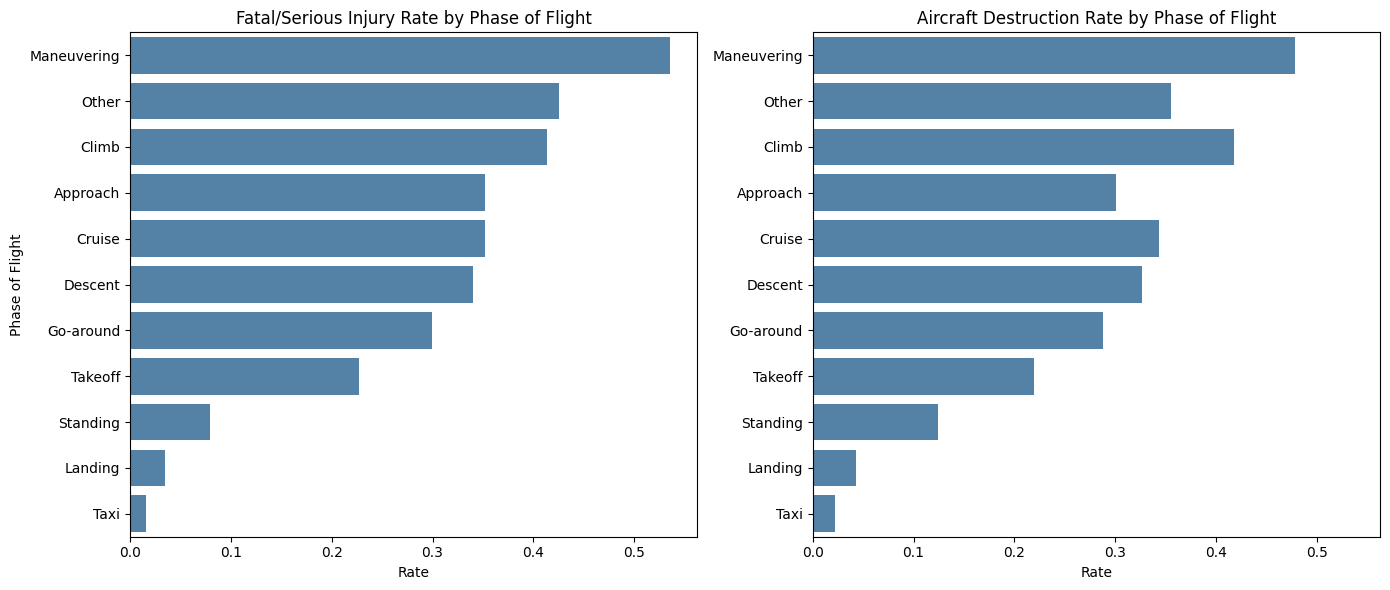

In [22]:
# PLOTTING: PHASE OF FLIGHT VS. INJURY AND DESTRUCTION RATES

phase_plot = phase_stats.reset_index()

fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharex=True)

# Left: injury rate
sns.barplot(data=phase_plot, x='injury_rate', y='Broad.phase.of.flight', color='steelblue', ax=axes[0])
axes[0].set_title('Fatal/Serious Injury Rate by Phase of Flight')
axes[0].set_xlabel('Rate')
axes[0].set_ylabel('Phase of Flight')

# Right: destruction rate (same phase order as the left plot)
sns.barplot(data=phase_plot, x='destroyed_rate', y='Broad.phase.of.flight', color='steelblue', ax=axes[1])
axes[1].set_title('Aircraft Destruction Rate by Phase of Flight')
axes[1].set_xlabel('Rate')
axes[1].set_ylabel('')

plt.tight_layout()
plt.show()

### Factor 2: Phase of Flight

**Analysis:** Compared the mean fatal/serious injury rate and the aircraft destruction rate for each broad phase of flight. Accidents with an unknown phase were excluded.

**Findings:**
- **Maneuvering is the most dangerous phase:** 54% fatal/serious injury rate and 48% of aircraft destroyed (4,657 accidents). 
- **Climb (41% injury, 42% destroyed)** is also high-risk. 
- **Approach, cruise, and descent** fall in the middle (34–35% injury rate).
- **Landing has the most accidents (11,983) but among the lowest severity** (3.5% injury, 4.3% destroyed). 
- **Taxi and Standing** (on the ground) are the least severe.
- The **"Other"** category has only 62 accidents, too few to draw reliable conclusions.
- Both measures (injury and destruction) rank the phases in almost the same order, which strengthens the finding.

**Key insight:** **How often an accident happens and how severe it is are different things.** Landing accidents are frequent but usually minor; maneuvering and climb accidents are less frequent but much more likely to be fatal or destroy the aircraft.

**Recommendation for the client:** Operations that involve a lot of low-altitude maneuvering carry higher severity risk and could be priced accordingly. Frequent but low-severity landing incidents mainly affect aircraft repair costs rather than injury claims.